# Corpus statistics (table + figure)

Composition of the locked GoalScope/OVReader eval corpus (`data/goalscope_eval.json`, built from `src.nrgs.data.QTASKS`). Per datatype: bank sub-tasks, eligible (non-trivial) frontiers, reps/frontier, eval datapoints, and example sub-tasks. Saves to `notebooks/Figures/corpus/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
import src.nrgs.data as D
from rich import print as rich_print
from rich.table import Table
GROUP='corpus'
meta=json.load(open('data/goalscope_eval.json'))['meta']
DTS=['int','list[int]','str','list[str]']
counts=meta['counts']; reps=meta['reps_per_frontier']
def bank(dt): return D.QTASKS[dt].predicates
def nontrivial(dt): return D.nontrivial_frontiers(dt)
for dt in DTS:
    print(dt, '| bank', len(bank(dt)), '| nontrivial', len(nontrivial(dt)),
          '| reps', reps[dt], '| datapoints', counts[dt])

int | bank 16 | nontrivial 13 | reps 5 | datapoints 65
list[int] | bank 16 | nontrivial 12 | reps 5 | datapoints 60
str | bank 16 | nontrivial 16 | reps 4 | datapoints 64
list[str] | bank 16 | nontrivial 16 | reps 4 | datapoints 64


                                      Eval corpus composition (per datatype)                                       
┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ datatype ┃ #sub-tasks ┃ #non-trivial ┃ reps/frontier ┃ #datapoints ┃ example sub-tasks                          ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ int      │ 16         │ 13           │ 5             │ 65          │ whether the number is even, whether the    │
│          │            │              │               │             │ number is positive, the number of digits   │
│ list     │ 16         │ 12           │ 5             │ 60          │ whether any value is even, the sum of all  │
│          │            │              │               │             │ values, the largest value                  │
│ str      │ 16         │ 16           │ 4             │ 64          │ whether the string is a palindrome, the    │
│          │            │              │               │             │ length of the string, the number of vowels │
│ list     │ 16         │ 16           │ 4             │ 64          │ whether any word is a palindrome, the      │
│          │            │              │               │             │ total number of characters across all      │
│          │            │              │               │             │ words, the number of words longer than     │
│          │            │              │               │             │ five characters                            │
│ total    │            │              │               │ 253         │                                            │
└──────────┴────────────┴──────────────┴───────────────┴─────────────┴────────────────────────────────────────────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/corpus/corpus_composition.tex


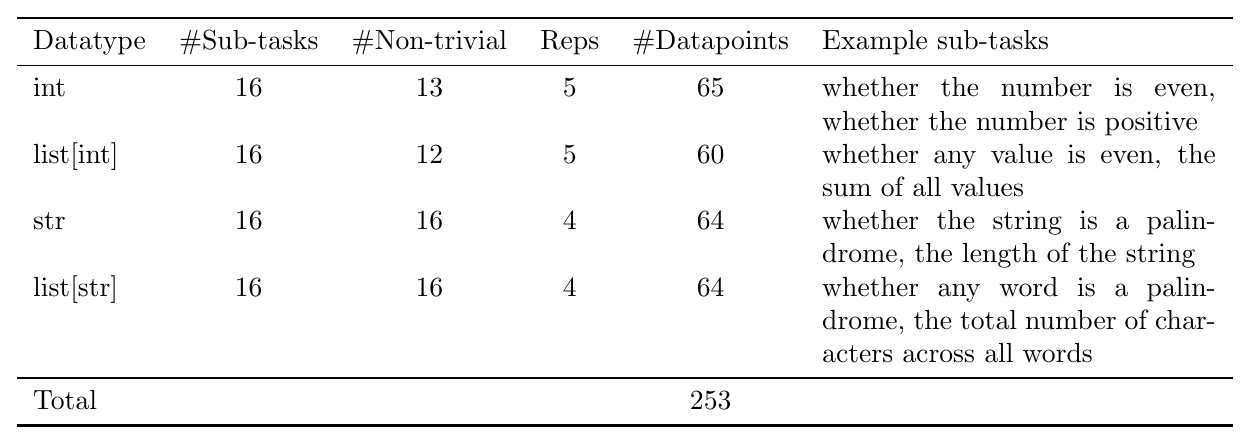

In [2]:
# rich table + .tex
def examples(dt,k=3):
    return ', '.join(p.description for p in bank(dt)[:k])
t=Table(title='Eval corpus composition (per datatype)')
for c in ['datatype','#sub-tasks','#non-trivial','reps/frontier','#datapoints','example sub-tasks']:
    t.add_column(c, overflow='fold')
for dt in DTS:
    t.add_row(dt, str(len(bank(dt))), str(len(nontrivial(dt))), str(reps[dt]), str(counts[dt]), examples(dt))
t.add_row('[b]total[/b]','','','',f"[b]{sum(counts.values())}[/b]",'')
rich_print(t)
def esc(s): return s.replace('_','\\_').replace('[','{[}').replace(']','{]}')
hdr='Datatype & \\#Sub-tasks & \\#Non-trivial & Reps & \\#Datapoints & Example sub-tasks'
body=' \\\\\n'.join(esc(dt)+f' & {len(bank(dt))} & {len(nontrivial(dt))} & {reps[dt]} & {counts[dt]} & '+esc(examples(dt,2)) for dt in DTS)
body+=f' \\\\\n\\midrule\nTotal & & & & {sum(counts.values())} & '
tex='\\begin{tabular}{lccccp{5cm}}\n\\toprule\n'+hdr+' \\\\\n\\midrule\n'+body+' \\\\\n\\bottomrule\n\\end{tabular}'
print('wrote', F.save_table(tex, GROUP, 'corpus_composition'))
img=F.render_latex_table(tex); img if img is not None else rich_print('[dim](latex preview unavailable)[/dim]')